
 EVALUATING TRAINING SET 
Processing 96 match files from Training/Ancient...
--- Computing F-1 Scores (1841 total valid rounds) ---
Epoch   0 | F-1 Score (Macro): 0.5148
Epoch  10 | F-1 Score (Macro): 0.5300
Epoch  20 | F-1 Score (Macro): 0.5445
Epoch  30 | F-1 Score (Macro): 0.5833
Epoch  40 | F-1 Score (Macro): 0.6219
Epoch  50 | F-1 Score (Macro): 0.6436
Epoch  60 | F-1 Score (Macro): 0.6670
Epoch End | F-1 Score (Macro): 0.6904


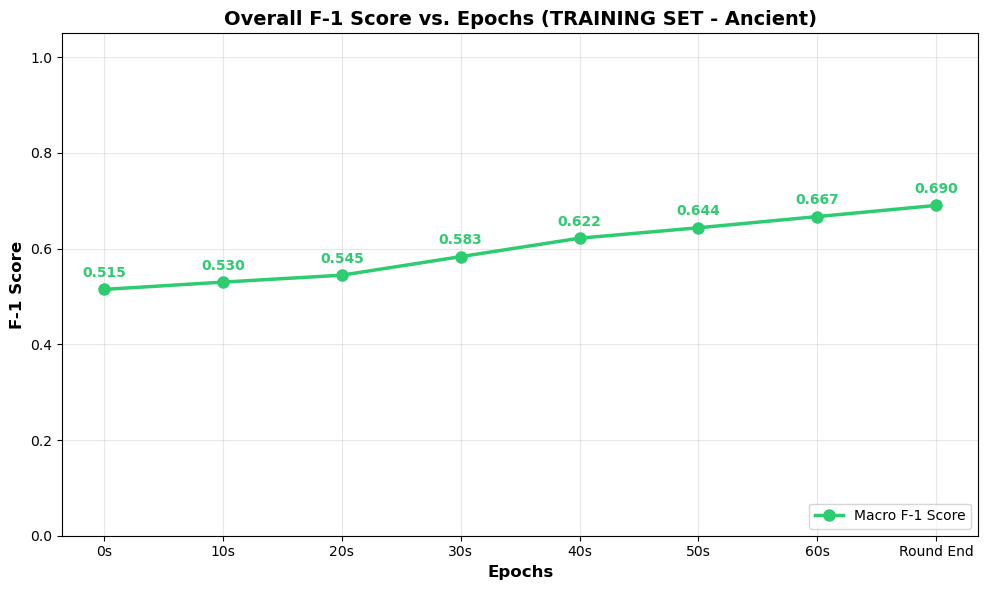


 EVALUATING TESTING SET 
Processing 23 match files from Testing/Ancient...
--- Computing F-1 Scores (458 total valid rounds) ---
Epoch   0 | F-1 Score (Macro): 0.5173
Epoch  10 | F-1 Score (Macro): 0.5454
Epoch  20 | F-1 Score (Macro): 0.5829
Epoch  30 | F-1 Score (Macro): 0.6178
Epoch  40 | F-1 Score (Macro): 0.6441
Epoch  50 | F-1 Score (Macro): 0.6812
Epoch  60 | F-1 Score (Macro): 0.6877
Epoch End | F-1 Score (Macro): 0.7183


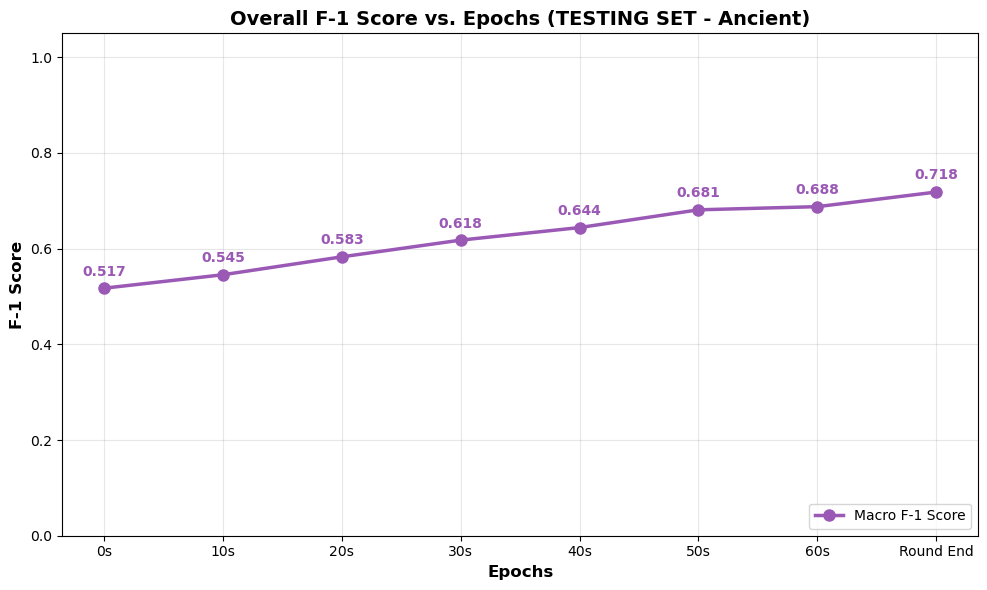

In [1]:
import polars as pl
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import f1_score

# ==========================================
# 1. CONFIGURATION & PATHS
# ==========================================
TRAIN_RESULTS_DIR = Path(r"D:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\Results\STOMs\WP_DAC_02\Training\Ancient")
TEST_RESULTS_DIR = Path(r"D:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\Results\STOMs\WP_DAC_02\Testing\Ancient")

EPOCHS = ["0", "10", "20", "30", "40", "50", "60", "End"]

# ==========================================
# 2. DATA RETRIEVAL & METRIC COMPUTATION
# ==========================================
def compute_overall_f1_scores(results_dir):
    """
    Parses all match result CSVs, extracts predictions and actual winners,
    and computes the overall macro F-1 score per epoch across all matches.
    """
    if not results_dir.exists():
        print(f"Error: Directory does not exist -> {results_dir}")
        return None

    csv_files = list(results_dir.glob("*.csv"))
    if not csv_files:
        print(f"No CSV files found in -> {results_dir}")
        return None

    print(f"Processing {len(csv_files)} match files from {results_dir.parent.name}/{results_dir.name}...")

    # Dictionaries to aggregate true labels and predictions for each epoch across all matches
    all_y_true = {e: [] for e in EPOCHS}
    all_y_pred = {e: [] for e in EPOCHS}

    for filepath in csv_files:
        try:
            df = pl.read_csv(filepath)
            
            # Ensure the actual winner column exists and drop rows with unknown/null winners
            if "actual_winner" not in df.columns:
                continue
                
            # Filter out any 'Unknown' or invalid labels just in case
            df_valid = df.filter(pl.col("actual_winner").is_in(["CT", "T"]))
            
            if df_valid.is_empty():
                continue
                
            actual_winners = df_valid["actual_winner"].to_list()
            
            for e in EPOCHS:
                pred_col = f"Pred_{e}"
                if pred_col in df_valid.columns:
                    predictions = df_valid[pred_col].to_list()
                    all_y_pred[e].extend(predictions)
                    all_y_true[e].extend(actual_winners)
                    
        except Exception as ex:
            print(f"Error processing {filepath.name}: {ex}")

    # Compute F-1 scores
    f1_scores = []
    print(f"--- Computing F-1 Scores ({len(all_y_true['0'])} total valid rounds) ---")
    for e in EPOCHS:
        if all_y_true[e] and all_y_pred[e]:
            # Using macro average to treat both classes (CT and T) equally
            f1 = f1_score(all_y_true[e], all_y_pred[e], average="macro")
            f1_scores.append(f1)
            print(f"Epoch {e:>3} | F-1 Score (Macro): {f1:.4f}")
        else:
            f1_scores.append(0.0)
            print(f"Epoch {e:>3} | No valid data")

    return f1_scores

# ==========================================
# 3. VISUALIZATION
# ==========================================
def plot_f1_vs_epochs(f1_scores, title, color):
    """Generates a line plot for F-1 score vs. epochs."""
    if not f1_scores:
        return

    plt.figure(figsize=(10, 6))
    
    # Format x-axis labels
    x_labels = [f"{e}s" if e != "End" else "Round End" for e in EPOCHS]
    
    # Plotting the data
    plt.plot(x_labels, f1_scores, marker='o', markersize=8, color=color, linewidth=2.5, label="Macro F-1 Score")
    
    # Formatting
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel("Epochs", fontsize=12, fontweight='bold')
    plt.ylabel("F-1 Score", fontsize=12, fontweight='bold')
    
    # Set y-axis bounds strictly between 0 and 1.05 for clean viewing
    plt.ylim(0.0, 1.05)
    
    # Adding data labels to points
    for i, f1 in enumerate(f1_scores):
        plt.text(i, f1 + 0.02, f"{f1:.3f}", ha='center', va='bottom', fontsize=10, fontweight='bold', color=color)

    plt.grid(True, alpha=0.3)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

# ==========================================
# MAIN EXECUTION
# ==========================================
if __name__ == "__main__":
    # --- Steps 1, 2 & 3: Training Data Evaluation & Visualization ---
    print("\n" + "="*50)
    print(" EVALUATING TRAINING SET ")
    print("="*50)
    train_f1_scores = compute_overall_f1_scores(TRAIN_RESULTS_DIR)
    
    if train_f1_scores:
        plot_f1_vs_epochs(
            train_f1_scores, 
            "Overall F-1 Score vs. Epochs (TRAINING SET - Ancient)", 
            color="#2ecc71" # Green color for training
        )

    # --- Step 4: Testing Data Evaluation & Visualization ---
    print("\n" + "="*50)
    print(" EVALUATING TESTING SET ")
    print("="*50)
    test_f1_scores = compute_overall_f1_scores(TEST_RESULTS_DIR)
    
    if test_f1_scores:
        plot_f1_vs_epochs(
            test_f1_scores, 
            "Overall F-1 Score vs. Epochs (TESTING SET - Ancient)", 
            color="#9b59b6" # Purple color for testing
        )